Preparação
* wget <dados-de-treinamento>
* git clone https://github.com/dmlc/mxnet-notebooks

In [1]:
import mxnet as mx
mx.__version__

/home/ec2-user/anaconda3/envs/mxnet_p27/lib/python2.7/site-packages/urllib3/contrib/pyopenssl.py:46: DeprecationWarning: OpenSSL.rand is deprecated - you should use os.urandom instead
  import OpenSSL.SSL


'1.0.0'

In [2]:
!conda install --yes -c conda-forge pydicom

Fetching package metadata .............
Solving package specifications: .

# All requested packages already installed.
# packages in environment at /home/ec2-user/anaconda3/envs/mxnet_p27:
#
pydicom                   0.9.9                    py27_0    conda-forge


In [3]:
import csv
import pandas as pd

data = pd.read_csv('https://s3.amazonaws.com/brasil.sp.summit.2017/pacientes-db/train.csv')
print data.head()


   Id  Systole  Diastole
0   1    108.3     246.7
1   2     54.6     137.2
2   3     32.7      99.3
3   4     57.7     154.5
4   5     83.3     235.5


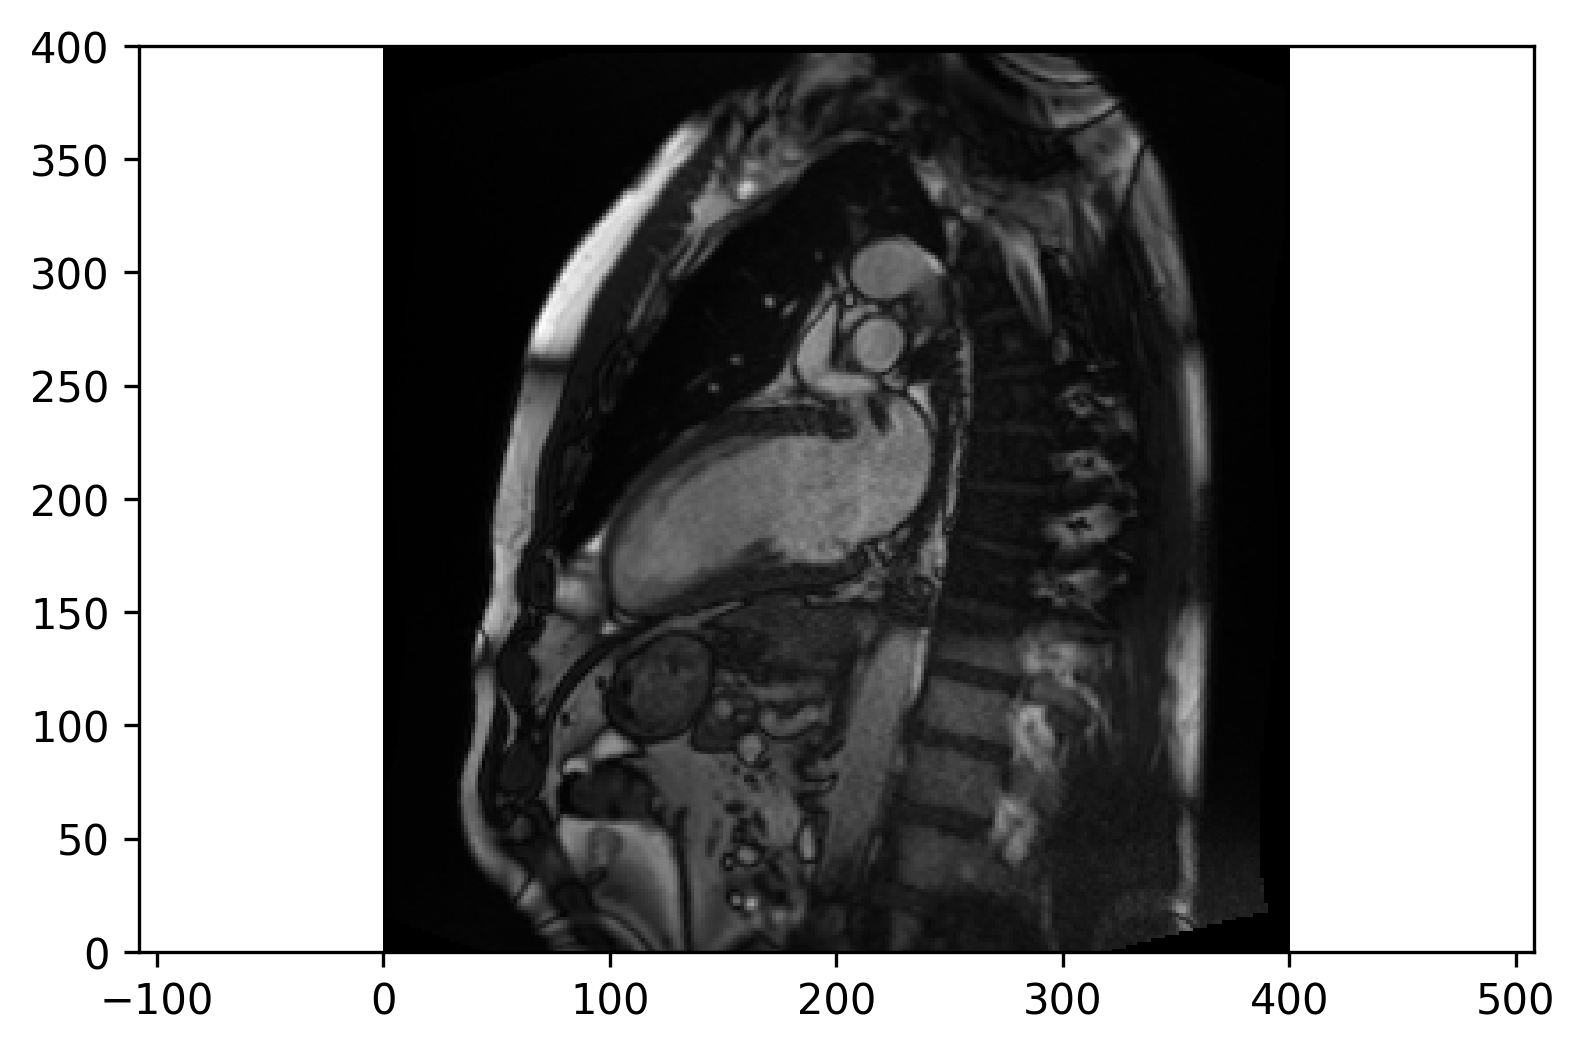

In [4]:
import dicom
import boto3
import csv
import numpy
import urllib
from matplotlib import pyplot, cm
import os

import pandas as pd
import boto

PathDicom = 'paciente-db'
data_file = 'IM-4572-0001.dcm'

if not os.path.exists(PathDicom):
    !mkdir paciente-db

print('Downloading exame do paciente...')
urllib.urlretrieve("https://s3.amazonaws.com/brasil.sp.summit.2017/pacientes-db/train-data/1/study/2ch_21/%s" % data_file, PathDicom + "/%s" % data_file)

#PathDicom = "paciente-1"

lstFilesDCM = []  # create an empty list
for dirName, subdirList, fileList in os.walk(PathDicom):
    for filename in fileList:
        if ".dcm" in filename.lower():  # check whether the file's DICOM
            lstFilesDCM.append(os.path.join(dirName,filename))

# Leitura do arquivo DCOM
RefDs = dicom.read_file(lstFilesDCM[0])

# Carga das dimensões baseado no numero de linhas, colunas, and slices (em torno no eixo Z)
ConstPixelDims = (int(RefDs.Rows), int(RefDs.Columns), len(lstFilesDCM))

# Verificar a distancia de pontos (mm)
ConstPixelSpacing = (float(RefDs.PixelSpacing[0]), float(RefDs.PixelSpacing[1]), float(RefDs.SliceThickness))

x = numpy.arange(0.0, (ConstPixelDims[0]+1)*ConstPixelSpacing[0], ConstPixelSpacing[0])
y = numpy.arange(0.0, (ConstPixelDims[1]+1)*ConstPixelSpacing[1], ConstPixelSpacing[1])
z = numpy.arange(0.0, (ConstPixelDims[2]+1)*ConstPixelSpacing[2], ConstPixelSpacing[2])

# Definição do array baseado em'ConstPixelDims'
ArrayDicom = numpy.zeros(ConstPixelDims, dtype=RefDs.pixel_array.dtype)

# Loop pelos frames (time series)
for filenameDCM in lstFilesDCM:
    # leitura
    ds = dicom.read_file(filenameDCM)
    # armazenamento da imagem original
    ArrayDicom[:, :, lstFilesDCM.index(filenameDCM)] = ds.pixel_array  

#Plotar a imagens na dimensão apropriada
pyplot.figure(dpi=300)
pyplot.axes().set_aspect('equal', 'datalim')
pyplot.set_cmap(pyplot.gray())
pyplot.pcolormesh(x, y, numpy.flipud(ArrayDicom[:, :, 0]))
pyplot.show()

# Leitura de imagens de Ressonância Magnética

## Carga de dados

In [5]:
import numpy as np
import os
import urllib
import gzip
import struct

def download_data(url, force_download=True): 
    fname = url.split("/")[-1]
    if force_download or not os.path.exists(fname):
        urllib.urlretrieve(url, fname)
    return fname

def read_data(label_url, image_url):
    with gzip.open(download_data(label_url)) as flbl:
        magic, num = struct.unpack(">II", flbl.read(8))
        label = np.fromstring(flbl.read(), dtype=np.int8)
    with gzip.open(download_data(image_url), 'rb') as fimg:
        magic, num, rows, cols = struct.unpack(">IIII", fimg.read(16))
        image = np.fromstring(fimg.read(), dtype=np.uint8).reshape(len(label), rows, cols)
    return (label, image)

path='https://s3.amazonaws.com/brasil.sp.summit.2017/pacientes-db/'
(train_lbl, train_img) = read_data(
    path+'train-sistole-diastole.gz', path+'train-ressonancia.gz')
(val_lbl, val_img) = read_data(
    path+'test-sistole-diastole.gz', path+'test-ressonancia.gz')

Imagens carregadas a associadas com os valores de sistole e diastole

In [6]:
import mxnet as mx

def to4d(img):
    return img.reshape(img.shape[0], 1, 28, 28).astype(np.float32)/255

batch_size = 100
train_iter = mx.io.NDArrayIter(to4d(train_img), train_lbl, batch_size, shuffle=True)
val_iter = mx.io.NDArrayIter(to4d(val_img), val_lbl, batch_size)

# Convolutional Network
<img src="https://raw.githubusercontent.com/dmlc/web-data/master/mxnet/image/conv_mnist.png" style="height: 50%; width: 75%;">

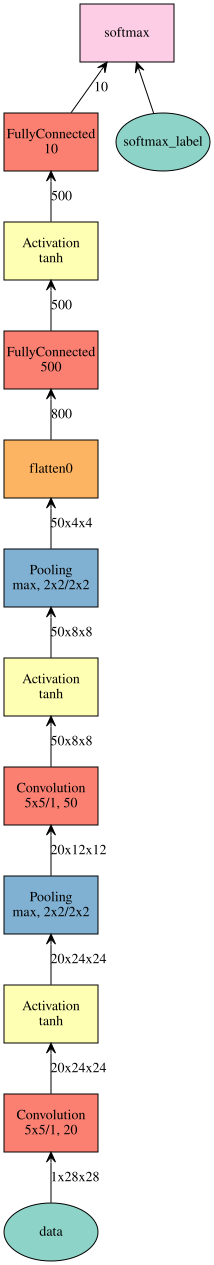

In [7]:
data = mx.symbol.Variable('data')
# first conv layer
conv1 = mx.sym.Convolution(data=data, kernel=(5,5), num_filter=20)
tanh1 = mx.sym.Activation(data=conv1, act_type="tanh")
pool1 = mx.sym.Pooling(data=tanh1, pool_type="max", kernel=(2,2), stride=(2,2))
# second conv layer
conv2 = mx.sym.Convolution(data=pool1, kernel=(5,5), num_filter=50)
tanh2 = mx.sym.Activation(data=conv2, act_type="tanh")
pool2 = mx.sym.Pooling(data=tanh2, pool_type="max", kernel=(2,2), stride=(2,2))
# first fullc layer
flatten = mx.sym.Flatten(data=pool2)
fc1 = mx.symbol.FullyConnected(data=flatten, num_hidden=500)
tanh3 = mx.sym.Activation(data=fc1, act_type="tanh")
# second fullc
fc2 = mx.sym.FullyConnected(data=tanh3, num_hidden=10)
# softmax loss
lenet = mx.sym.SoftmaxOutput(data=fc2, name='softmax')
shape = {"data" : (batch_size, 1, 28, 28)}
mx.viz.plot_network(symbol=lenet, shape=shape)

# Multilayer Perceptron

$$ \left[\frac{\exp(x_{i1})}{\sum_{j=1}^m \exp(x_{ij})},\ldots, \frac{\exp(x_{im})}{\sum_{j=1}^m \exp(x_{ij})}\right] $$


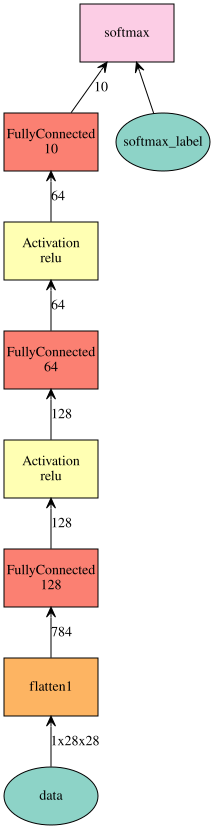

In [8]:
# Create a place holder variable for the input data
data = mx.sym.Variable('data')
# Flatten the data from 4-D shape (batch_size, num_channel, width, height) 
# into 2-D (batch_size, num_channel*width*height)
data = mx.sym.Flatten(data=data)

# The first fully-connected layer
fc1  = mx.sym.FullyConnected(data=data, name='fc1', num_hidden=128)
# Apply relu to the output of the first fully-connnected layer
act1 = mx.sym.Activation(data=fc1, name='relu1', act_type="relu")

# The second fully-connected layer and the according activation function
fc2  = mx.sym.FullyConnected(data=act1, name='fc2', num_hidden = 64)
act2 = mx.sym.Activation(data=fc2, name='relu2', act_type="relu")

# The thrid fully-connected layer, note that the hidden size should be 10, which is the number of unique digits
fc3  = mx.sym.FullyConnected(data=act2, name='fc3', num_hidden=10)
# The softmax and loss layer
mlp  = mx.sym.SoftmaxOutput(data=fc3, name='softmax')

# We visualize the network structure with output size (the batch_size is ignored.)
shape = {"data" : (batch_size, 1, 28, 28)}
mx.viz.plot_network(symbol=mlp, shape=shape)

# Inicio do treinamento 

In [9]:
import logging
logging.getLogger().setLevel(logging.DEBUG)

model = mx.model.FeedForward(
    symbol = mlp,       # network structure
    num_epoch = 5,     # number of data passes for training 
    learning_rate = 0.1 # learning rate of SGD 
)
model.fit(
    X=train_iter,       # training data
    eval_data=val_iter, # validation data
    batch_end_callback = mx.callback.Speedometer(batch_size, 200) # output progress for each 200 data batches
)

/home/ec2-user/anaconda3/envs/mxnet_p27/lib/python2.7/site-packages/ipykernel/__main__.py:7: DeprecationWarning: mxnet.model.FeedForward has been deprecated. Please use mxnet.mod.Module instead.
/home/ec2-user/anaconda3/envs/mxnet_p27/lib/python2.7/site-packages/mxnet/model.py:573: DeprecationWarning: Calling initializer with init(str, NDArray) has been deprecated.please use init(mx.init.InitDesc(...), NDArray) instead.
  self.initializer(k, v)
INFO:root:Start training with [cpu(0)]
INFO:root:Epoch[0] Batch [200]	Speed: 73917.75 samples/sec	accuracy=0.107200
INFO:root:Epoch[0] Batch [400]	Speed: 72182.61 samples/sec	accuracy=0.114950
INFO:root:Epoch[0] Batch [600]	Speed: 73805.63 samples/sec	accuracy=0.195450
INFO:root:Epoch[0] Resetting Data Iterator
INFO:root:Epoch[0] Time cost=0.825
INFO:root:Epoch[0] Validation-accuracy=0.356700
INFO:root:Epoch[1] Batch [200]	Speed: 73505.62 samples/sec	accuracy=0.589000
INFO:root:Epoch[1] Batch [400]	Speed: 73688.16 samples/sec	accuracy=0.794450
I

Apos este treinamento, é possível prever um diagnóstico. 

In [ ]:
prob = model.predict(val_img[2:3].astype(np.float32)/255)[0]
assert max(prob) > 0.90, "Este exame clinico não foi conclusivo"
print 'Probabilidade de ataque cardiaco %f' % (max(prob))